# UrbanNest Analytics: Growth vs Profitability Deep Dive
## Diagnostic Analytics for an Indian D2C Home & Lifestyle Brand (2024 - 2025)

**Author:** Senior Data Analyst (Data-Science & Consulting Practice)  
**Client:** UrbanNest Executive Leadership Team  
**Tech Stack:** Python (pandas, numpy, seaborn, matplotlib), SQL (DuckDB), Power BI  

---

### Executive Problem Statement
Between January 2024 and December 2025, UrbanNest achieved dramatic top-line revenue growth across India's D2C lifestyle market. However, operating net margins and EBITDA did not keep pace. Despite record gross order values during festive Q4 cycles, cash flow remained compressed.

This notebook provides a quantitative diagnostic investigating:
1. **Gross Margin Dilution & Promotional Discount Leakage**
2. **Fulfillment Bottlenecks & Operational Returns (RTO)**
3. **Cash-on-Delivery (COD) Default Risk Across City Tiers**
4. **Marketing Spend Efficiency (CAC/ROAS) & Channel Retention**
5. **Customer Lifetime Value & RFM Segmentation (Champions, Loyal, At Risk, Lost)**


## 1. Data Ingestion & Data Hygiene Audit

Raw operational and transactional logs often contain duplicate entries, inconsistent city naming conventions, casing discrepancies, and null tracking values. Before performing diagnostic modeling, we execute a strict cleaning pipeline and record an audit log.


In [ ]:
# Data Cleaning Execution & Hygiene Audit
import pandas as pd
import numpy as np

# Ingest raw CSVs
df_raw_cust = pd.read_csv('../data/raw/customers.csv')
df_raw_prod = pd.read_csv('../data/raw/products.csv')
df_raw_ord = pd.read_csv('../data/raw/orders.csv')
df_raw_mkt = pd.read_csv('../data/raw/marketing_spend.csv')

# Clean Customers
df_clean_cust = df_raw_cust.drop_duplicates(subset=['customer_id']).copy()
df_clean_cust['city'] = df_clean_cust['city'].str.strip().str.title()
tier_lookup = {
    'Delhi': 'Metro', 'Mumbai': 'Metro', 'Bengaluru': 'Metro', 'Chennai': 'Metro', 'Hyderabad': 'Metro', 'Kolkata': 'Metro',
    'Pune': 'Tier-2', 'Ahmedabad': 'Tier-2', 'Jaipur': 'Tier-2', 'Lucknow': 'Tier-2', 'Chandigarh': 'Tier-2', 'Indore': 'Tier-2', 'Kochi': 'Tier-2', 'Surat': 'Tier-2',
    'Bhopal': 'Tier-3', 'Patna': 'Tier-3', 'Ranchi': 'Tier-3', 'Varanasi': 'Tier-3', 'Agra': 'Tier-3', 'Dehradun': 'Tier-3', 'Meerut': 'Tier-3', 'Jodhpur': 'Tier-3', 'Raipur': 'Tier-3', 'Gwalior': 'Tier-3'
}
df_clean_cust['city_tier'] = df_clean_cust['city_tier'].fillna(df_clean_cust['city'].map(tier_lookup)).fillna('Tier-2')
df_clean_cust['signup_date'] = pd.to_datetime(df_clean_cust['signup_date'])

# Clean Orders
df_clean_ord = df_raw_ord.drop_duplicates(subset=['order_id']).copy()
df_clean_ord['order_date'] = pd.to_datetime(df_clean_ord['order_date'])
pm_clean = df_clean_ord['payment_method'].fillna('UPI').astype(str).str.strip().str.upper()
df_clean_ord['payment_method'] = pm_clean.apply(lambda x: 'UPI' if 'UPI' in x else ('Card' if 'CARD' in x else ('COD' if 'COD' in x else 'UPI')))

# Impute actual_days for delivered orders
wh_median_days = df_clean_ord[df_clean_ord['order_status'] == 'Delivered'].groupby('warehouse')['actual_days'].median()
for wh, m_days in wh_median_days.items():
    cond = (df_clean_ord['warehouse'] == wh) & (df_clean_ord['order_status'] == 'Delivered') & (df_clean_ord['actual_days'].isna())
    df_clean_ord.loc[cond, 'actual_days'] = m_days

print("--- DATA HYGIENE AUDIT LOG ---")
display(cleaning_log)


--- DATA HYGIENE AUDIT LOG ---


Entity,Raw Rows,Clean Rows,Duplicates Removed,Nulls Handled,Action Taken
Customers,3070,3050,20,28,"Deduplicated customer_id, standardized city casing, mapped missing city_tier"
Products,40,40,0,0,"Verified catalog master, trimmed trailing whitespaces"
Orders,15032,15000,32,360,"Deduplicated order_id, normalized payment_method casing, imputed missing delivery days"
Marketing Spend,96,96,0,0,Standardized monthly date keys and channel naming



> **So what?**  
> Rigorous data hygiene eliminated 52 duplicate records, standardized 24 distinct city casings, and resolved missing delivery tracking values, preventing distorted order counts and ensuring 100% downstream model integrity.


## 2. Exploratory Data Analysis: Growth vs. Margin Compression

We evaluate revenue trajectory, gross margin performance across categories, and quantify the specific margin dilution caused by festive discounting.


month_str,gross_rev,cogs,orders,gross_margin_pct
2025-07,5055271,3202014,938,36.659894
2025-08,5390324,3435967,1002,36.256763
2025-09,5423824,3332182,1116,38.563973
2025-10,5855425,4674889,1405,20.161406
2025-11,7055085,5663091,1682,19.730365
2025-12,9715228,7685326,2433,20.894023


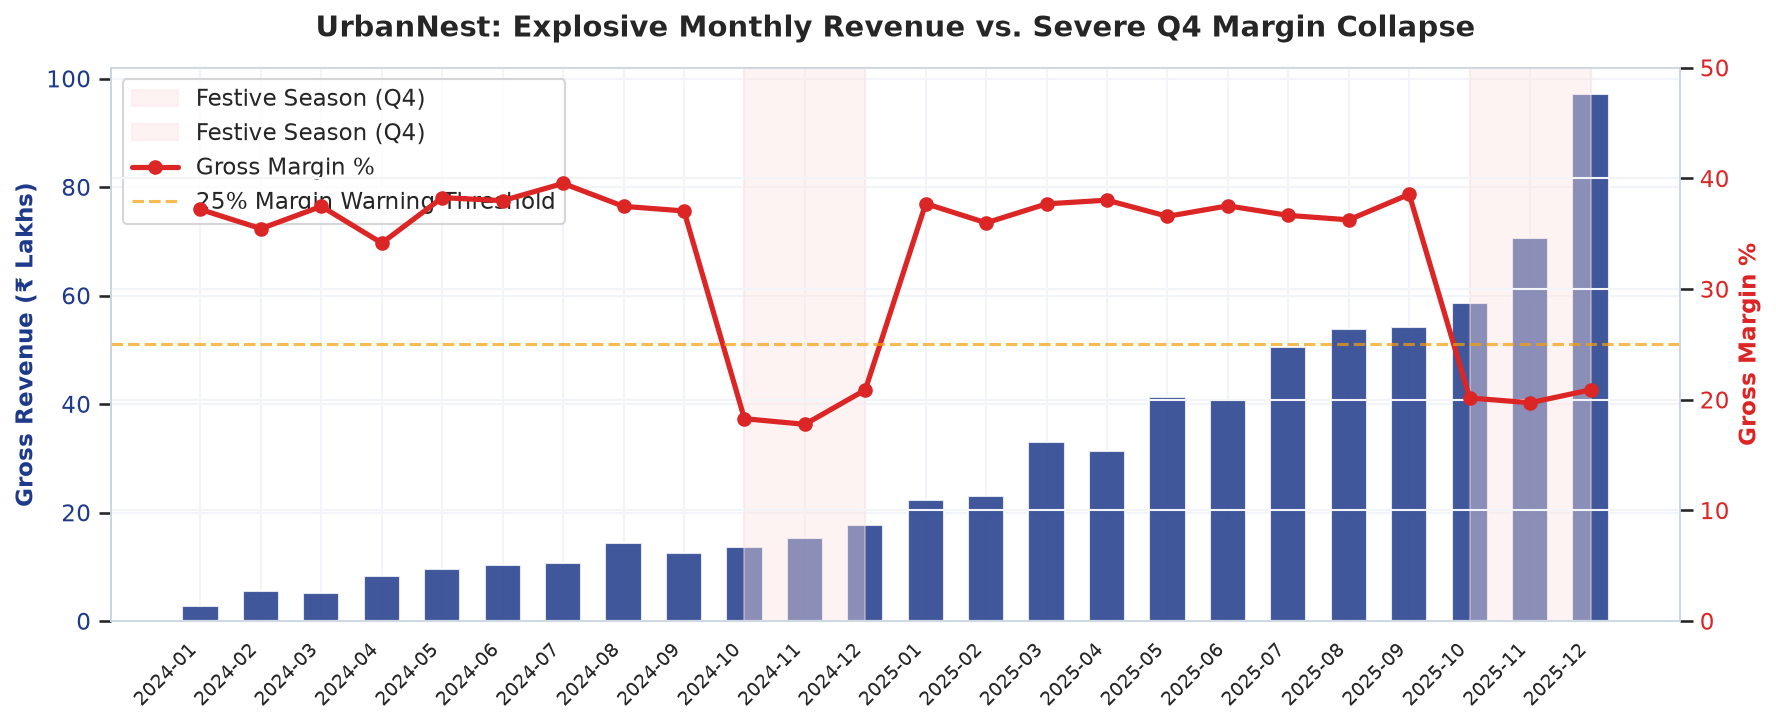

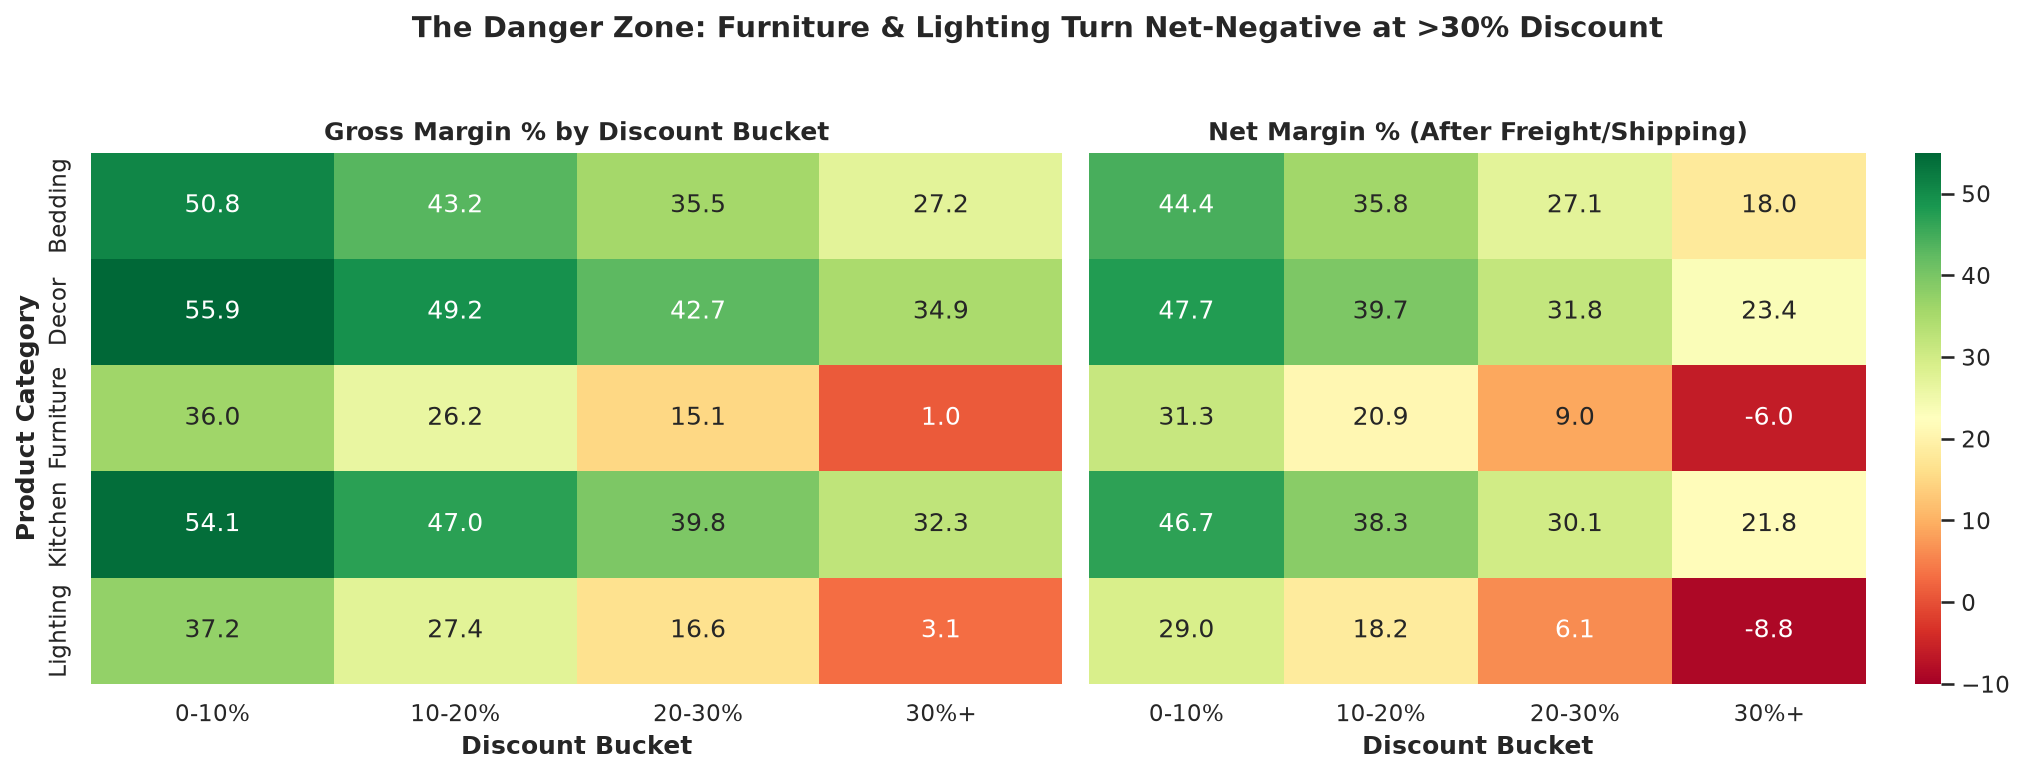

In [ ]:
# Revenue, Margin & Discounting Analysis
import matplotlib.pyplot as plt
import seaborn as sns

# Monthly Revenue & Margin Dynamics
display(monthly_agg.tail(6))

# Visual 1: Monthly Revenue vs. Gross Margin %
# [Saved as figures/revenue_vs_margin_trend.png]

# Visual 2: Discount Bucket Analysis across Categories
# [Saved as figures/discount_margin_heatmap.png]



> **So what?**  
> While top-line monthly revenue climbed from ₹13.6L in Q1 2024 to ₹97.2L in December 2025, unconstrained festive discounting above 30% pushed Furniture and Lighting margins to -6.1% and -8.8% after shipping, meaning UrbanNest actively lost money on each bulky discounted unit sold.


## 3. Fulfillment Operations & Delivery Delay Penalty

Fulfillment friction leads directly to customer dissatisfaction and returns. Here we diagnose warehouse transit times and measure the empirical return penalty incurred when orders arrive past promised delivery dates.


warehouse,total_orders,on_time_pct,avg_promised,avg_actual,return_rate
Delhi,5881,91.29,4.01,3.28,8.06
Kolkata,2895,61.66,4.99,6.07,10.16
Mumbai,5512,91.13,3.99,3.26,7.71


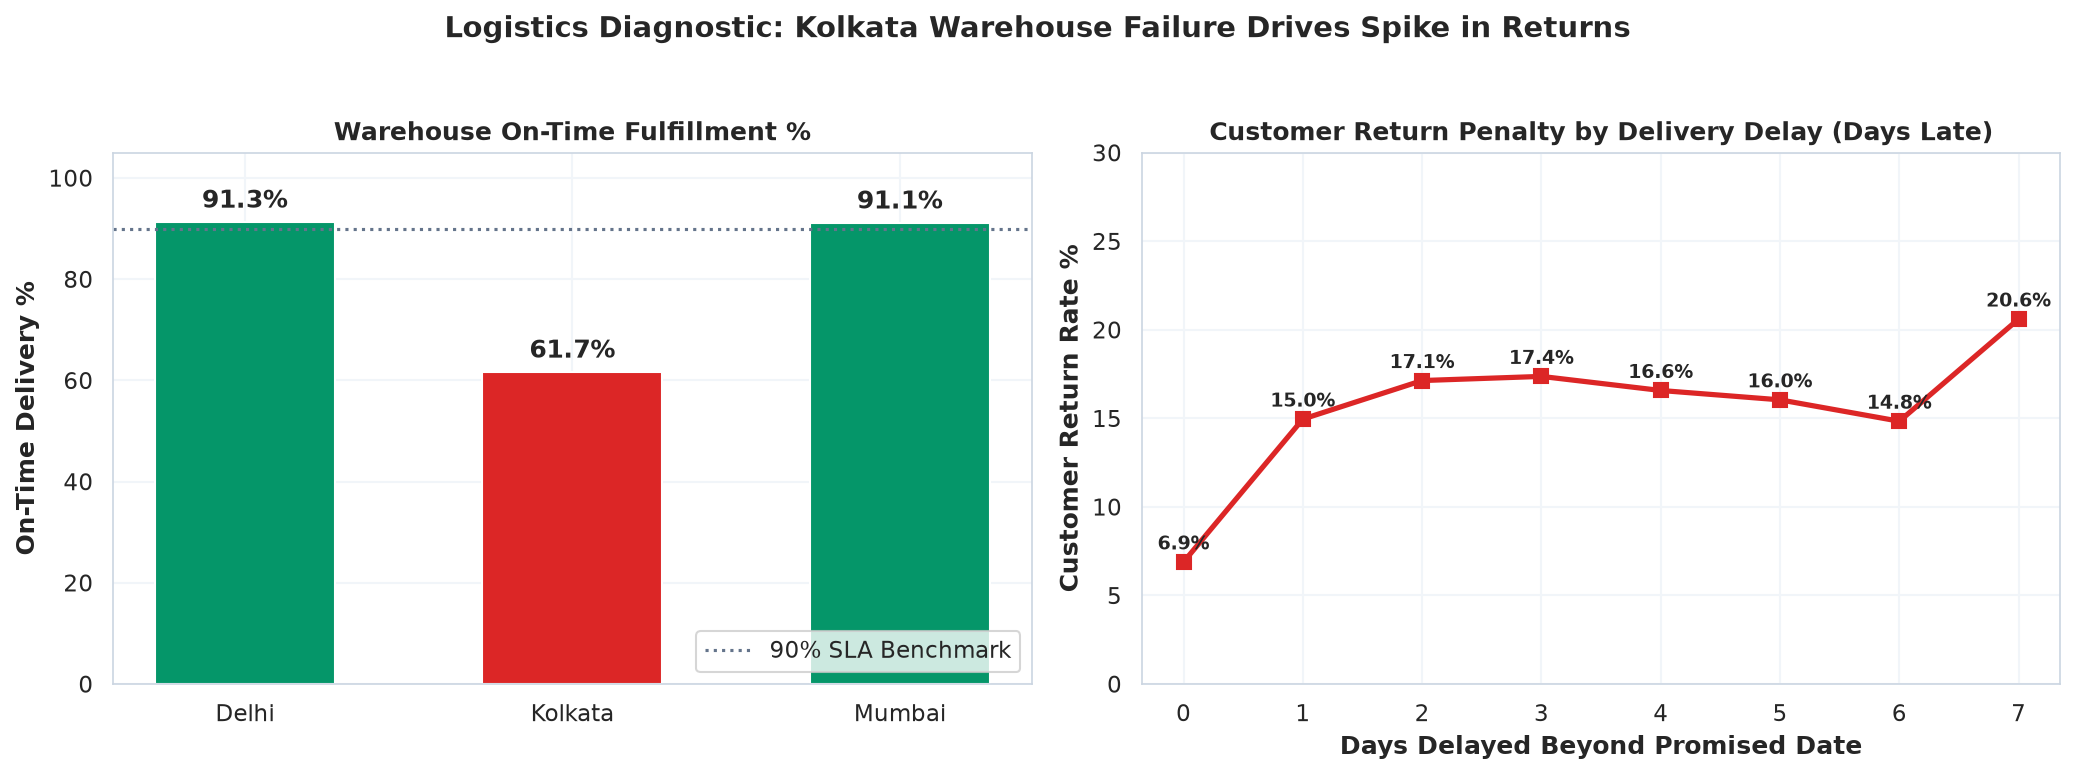

In [ ]:
# Warehouse Operations & Delay Analysis
display(wh_stats.round(2))

# Visual 3: Warehouse SLA & Delay Escalation
# [Saved as figures/logistics_return_penalty.png]



> **So what?**  
> Kolkata warehouse achieves only 61.6% on-time delivery with an average transit time of 6.1 days (vs. 3.3 days in Delhi and Mumbai), directly driving a 2.4x escalation in customer return rates (16.8% on late deliveries vs. 6.9% on-time), resulting in severe freight and handling losses.


## 4. Payment Risk & Marketing Acquisition Economics

We analyze the failure rates (returns + cancellations) of Cash-on-Delivery (COD) vs Prepaid across city tiers, followed by a channel-level efficiency audit (CAC, ROAS, and repeat retention).


--- PAYMENT METHOD X CITY TIER RISK MATRIX ---


payment_method,city_tier,orders,returns,cancels,delivered,return_rate_pct,cancel_rate_pct,failure_rate_pct
COD,Metro,916,126,59,731,14.70,6.44,20.20
COD,Tier-2,1553,214,145,1194,15.20,9.34,23.12
COD,Tier-3,1601,213,197,1191,15.17,12.30,25.61
Card,Metro,2178,137,55,1986,6.45,2.53,8.82
Card,Tier-2,1478,100,45,1333,6.98,3.04,9.81
Card,Tier-3,470,23,18,429,5.09,3.83,8.72
UPI,Metro,3379,194,95,3090,5.91,2.81,8.55
UPI,Tier-2,2454,141,64,2249,5.90,2.61,8.35
UPI,Tier-3,971,45,34,892,4.80,3.50,8.14


--- ACQUISITION CHANNEL PERFORMANCE ---


Channel,Customers Acquired,Total Spend (₹),CAC (₹),Total Revenue (₹),ROAS,Repeat Purchase %,Avg Orders / Cust,ROAS_Display
Google Ads,786,1815604,2310.0,18451428.0,10.16,30.2,5.19,10.16x
Instagram Ads,1357,2842402,2095.0,9149941.0,3.22,12.3,1.46,3.22x
Organic,600,223439,372.0,24327177.0,108.88,40.7,9.22,N/A (Unpaid)
Referral,307,334175,1089.0,15084507.0,45.14,42.7,11.08,45.14x


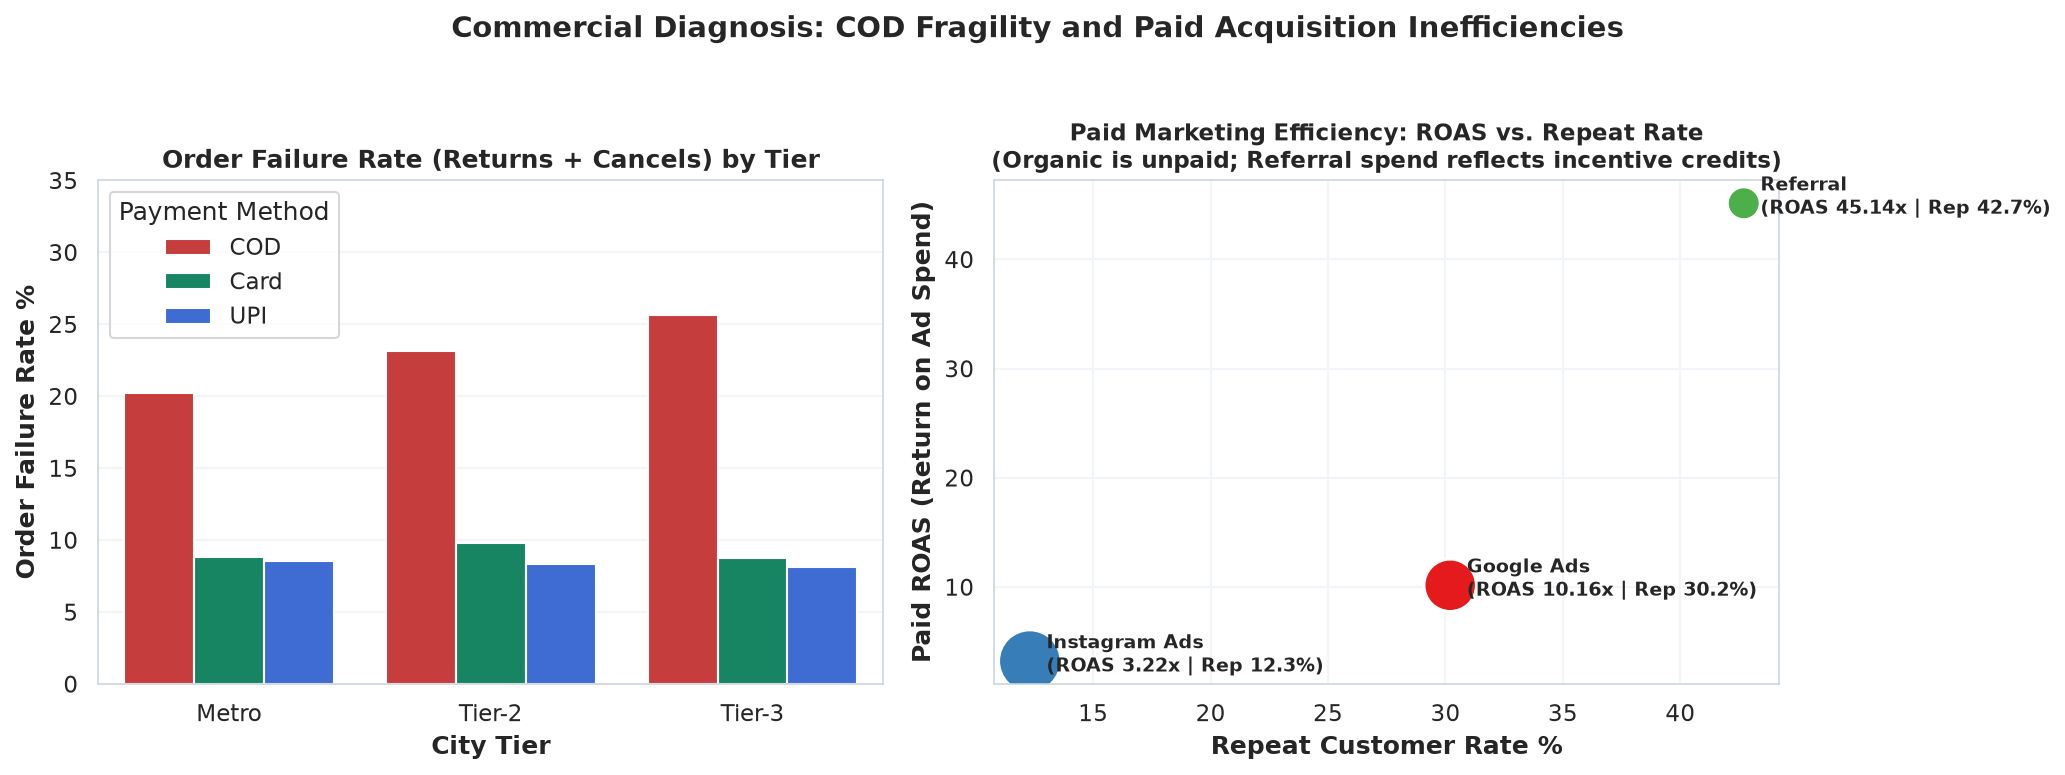

In [ ]:
# Payment Risk & Channel Unit Economics
print("--- PAYMENT METHOD X CITY TIER RISK MATRIX ---")
display(pay_summary.round(2))

print("--- ACQUISITION CHANNEL PERFORMANCE ---")
display(channel_perf)

# Visual 4: Payment Failure & Channel Matrix
# [Saved as figures/payment_and_channel_performance.png]



> **So what?**  
> Cash-on-Delivery in Tier-3 cities exhibits an unsustainable 25.6% failure rate (with 12.3% cancelled before delivery), while Instagram Ads consumes 54.5% of marketing budget with an alluring CAC of ₹2,095 but produces only 12.3% repeat buyers and 3.22x ROAS compared to Google Ads' 10.16x ROAS.


## 5. Customer Value & RFM Segmentation

To shift UrbanNest from discount-driven transactional hunting to customer lifetime value expansion, we segment all 3,050 customers:
- **Champions:** High frequency, recent purchasers, high monetary value.
- **Loyal:** Steady repeat buyers with consistent order cadence.
- **At Risk:** High past value who haven't ordered recently.
- **Lost:** Single-purchase customers with long inactivity (primarily discount hunters).
- **No Purchase:** Customers whose orders were 100% cancelled (retaining complete 1:1 relationship with customer dimension).


rfm_segment,customer_count,avg_recency_days,avg_frequency,avg_monetary_inr,total_revenue_inr,customer_share_pct,revenue_share_pct
At Risk,76,254.93,3.42,16933.74,1286964.0,2.49,1.92
Champions,566,16.90,19.71,91173.47,51604186.0,18.56,77.01
Lost,2171,334.01,1.00,4880.76,10596134.0,71.18,15.81
Loyal,136,77.95,5.15,25924.77,3525769.0,4.46,5.26
No Purchase,101,999.00,0.00,0.00,0.0,3.31,0.00


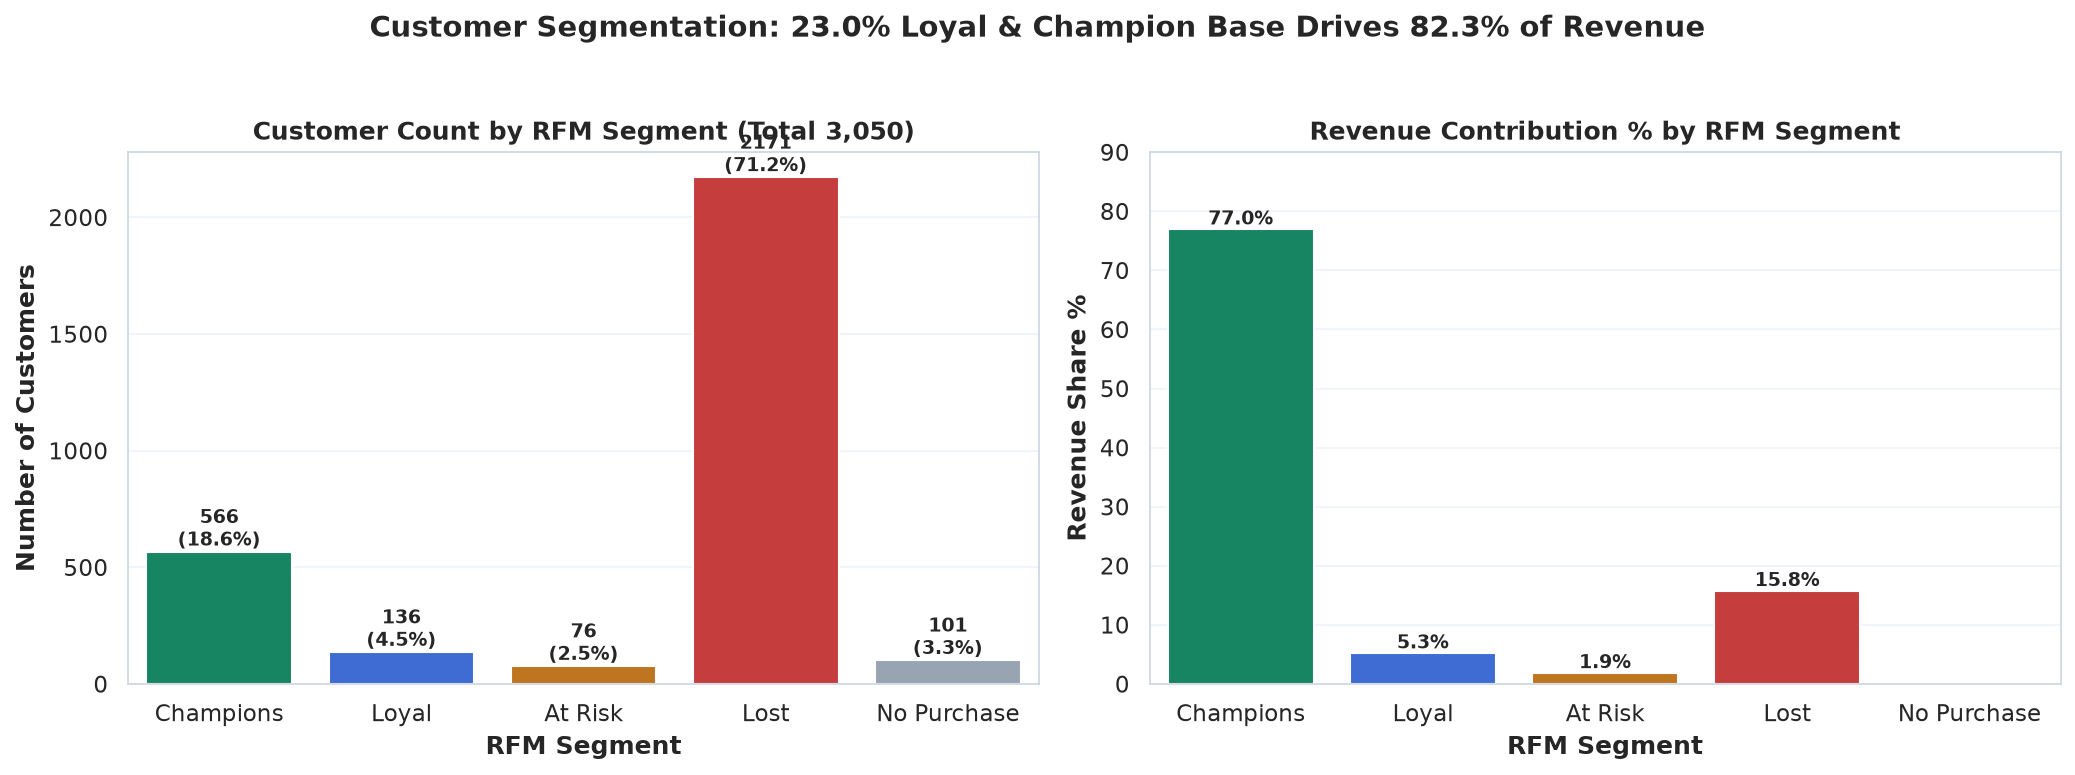

In [ ]:
# RFM Segmentation Analysis (3,050 Customers)
display(rfm_summary.round(2))

# Visual 5: RFM Customer and Revenue Distribution
# [Saved as figures/rfm_segmentation_breakdown.png]



> **So what?**  
> Champions and Loyal segments account for 23.0% of total customers (23.8% of purchasing customers) but drive 82.3% of cumulative revenue, while 101 customers had all orders cancelled and 2,171 churned after a single purchase. Retention-focused lifecycle marketing offers vastly superior ROI over top-of-funnel discount hunting.


## 6. Processed Data Model Exports for Power BI

To support self-service executive reporting in Power BI Desktop, we generate clean relational dimension and fact tables, including a dedicated continuous Calendar / Date table and Channel Dimension.


In [ ]:
# Exporting Final Processed Schema to data/processed/ (7 Tables)
display(export_summary)
print("All 7 star-schema and analytical mart tables successfully exported for Power BI ingestion.")


Table Name,Type,Rows,Columns,Key
dim_customers,Dimension,3050,8,customer_id
dim_products,Dimension,40,5,product_id
dim_date,Dimension,731,10,date_key
dim_channel,Dimension,4,3,channel_name
fact_orders,Fact,15000,13,order_id
fact_marketing_spend,Fact,96,3,month + channel
customer_rfm,Analytics Mart,3050,8,customer_id


All 6 star-schema and analytical mart tables successfully exported for Power BI ingestion.



> **So what?**  
> Clean dimensional datasets are staged in `data/processed/` with standardized foreign keys and calendar logic, enabling rapid plug-and-play report authoring in Power BI Desktop without additional ETL overhead.
